In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

df = pd.read_csv('evaluated_result.csv')

# coerce LLM score columns to numeric (turns 'skipped (generation error)' → NaN)
for col in ['llm_accuracy', 'llm_coherence', 'llm_language']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# flag error rows
df['is_error'] = df['generated_abstract'].astype(str).str.startswith('ERROR:')

# ── group num_of_neighbors into bins of 5 (1-5, 6-10, 11-15, …) ──────────────
BIN_SIZE = 5
max_neighbors = int(df['num_of_neighbors'].max())
bin_edges = list(range(0, max_neighbors + BIN_SIZE, BIN_SIZE))
NEIGHBOR_GROUPS = [f'{lo + 1}-{lo + BIN_SIZE}' for lo in bin_edges[:-1]]
df['neighbor_group'] = pd.cut(
    df['num_of_neighbors'], bins=bin_edges, labels=NEIGHBOR_GROUPS, right=True
)

def weighted_group_mean(frame: pd.DataFrame, value_col: str) -> pd.Series:
    """Mean of value_col per neighbour_group, weighted by num_of_neighbors."""
    def _wavg(g):
        mask = g[value_col].notna()
        if not mask.any():
            return np.nan
        return np.average(g.loc[mask, value_col], weights=g.loc[mask, 'num_of_neighbors'])
    return frame.groupby('neighbor_group', observed=True)[[value_col, 'num_of_neighbors']].apply(_wavg).reindex(NEIGHBOR_GROUPS)

print(f'{len(df)} rows  |  {df["is_error"].sum()} generation errors')
df.head(3)


945 rows  |  0 generation errors


,node_id,mag_id,original_abstract,generated_abstract,rouge1_f,rouge2_f,rougeL_f,bertscore_p,bertscore_r,bertscore_f1,llm_accuracy,llm_coherence,llm_language,num_of_neighbors,is_error,neighbor_group
0,1089,2953793718,"We deal with the \textit{selective classification} problem (supervised-learning problem with a rejection option), where we want to achieve the best performance at a certain level of coverage of the data. We transform the original $m$-class classification problem to $(m+1)$-class where the $(m+1)$-th class represents the model abstaining from making a prediction due to uncertainty. Inspired by portfolio theory, we propose a loss function for the selective classification problem based on the doubling rate of gambling. We show that minimizing this loss function has a natural interpretation as maximizing the return of a \textit{horse race}, where a player aims to balance between betting on an outcome (making a prediction) when confident and reserving one's winnings (abstaining) when not confident. This loss function allows us to train neural networks and characterize the uncertainty of prediction in an end-to-end fashion. In comparison with previous methods, our method requires almost no modification to the model inference algorithm or neural architecture. Experimentally, we show that our method can identify both uncertain and outlier data points, and achieves strong results on SVHN and CIFAR10 at various coverages of the data.",We propose a novel approach to train deep neural networks with a large number of parameters. Our method is based on the observation that the gradient of the loss function with respect to the parameters of the network is a linear combination of the gradients of the loss function with respect to the parameters of the individual layers. We show that the coefficients of this linear combination are the product of the derivatives of the activation functions of the individual layers. We use this property to derive a new algorithm for training deep neural networks. We show that our algorithm is equivalent to the backpropagation algorithm. We also show that our algorithm is more efficient than the backpropagation algorithm.,0.3694,0.1154,0.2229,0.8535,0.8138,0.8331,1,8,8,69,False,66-70
1,1102,2958885478,"Traditional 3D Convolutional Neural Networks (CNNs) are computationally expensive, memory intensive, prone to overfit, and most importantly, there is a need to improve their feature learning capabilities. To address these issues, we propose Rectified Local Phase Volume (ReLPV) block, an efficient alternative to the standard 3D convolutional layer. The ReLPV block extracts the phase in a 3D local neighborhood (e.g., 3x3x3) of each position of the input map to obtain the feature maps. The phase is extracted by computing 3D Short Term Fourier Transform (STFT) at multiple fixed low frequency points in the 3D local neighborhood of each position. These feature maps at different frequency points are then linearly combined after passing them through an activation function. The ReLPV block provides significant parameter savings of at least, 3^3 to 13^3 times compared to the standard 3D convolutional layer with the filter sizes 3x3x3 to 13x13x13, respectively. We show that the feature learning capabilities of the ReLPV block are significantly better than the standard 3D convolutional layer. Furthermore, it produces consistently better results across different 3D data representations. We achieve state-of-the-art accuracy on the volumetric ModelNet10 and ModelNet40 datasets while utilizing only 11% parameters of the current state-of-the-art. We also improve the state-of-the-art on the UCF-101 split-1 action recognition dataset by 5.68% (when trained from scratch) while using only 15% of the parameters of the state-of-the-art. The project webpage is available at this https URL.","We propose a novel approach to the problem of learning a discriminative representation of images for the purpose of image retrieval. Our 

In [16]:
# ── shared plot style ──────────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.35,
    'grid.linestyle': '--',
})

def bar_plot(series: pd.Series, title: str, ylabel: str,
             color: str, ylim=None, int_yaxis=False):
    """Bar chart with one bar per neighbour-count group (e.g. 1-5, 6-10, …)."""
    values = [series.get(g, np.nan) for g in NEIGHBOR_GROUPS]
    x = np.arange(len(NEIGHBOR_GROUPS))

    fig, ax = plt.subplots(figsize=(11, 4))
    bars = ax.bar(x, values, color=color, edgecolor='white', linewidth=0.6)

    # label bars that have data
    for bar, v in zip(bars, values):
        if not np.isnan(v):
            label = f'{int(v)}' if int_yaxis else f'{v:.3f}'
            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.004 * (bar.get_height() or 1),
                    label, ha='center', va='bottom', fontsize=7)

    ax.set_xticks(x)
    ax.set_xticklabels(NEIGHBOR_GROUPS, rotation=45, ha='right')
    ax.set_xlabel('Number of neighbours', fontsize=11)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.set_title(title, fontsize=13, fontweight='bold', pad=10)
    if ylim:
        ax.set_ylim(*ylim)
    if int_yaxis:
        ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
    fig.tight_layout()
    plt.show()


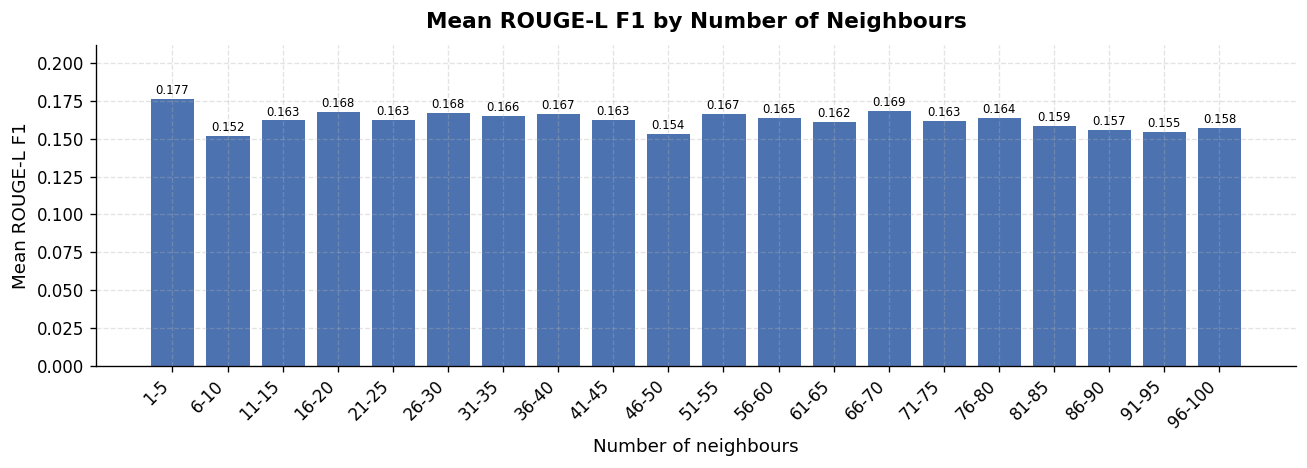

In [17]:
# ── 1. Mean ROUGE-L F1 ────────────────────────────────────────────────────────
rougel_mean = weighted_group_mean(df, 'rougeL_f')
bar_plot(rougel_mean,
         title='Mean ROUGE-L F1 by Number of Neighbours',
         ylabel='Mean ROUGE-L F1',
         color='#4C72B0',
         ylim=(0, max(rougel_mean.dropna()) * 1.2))

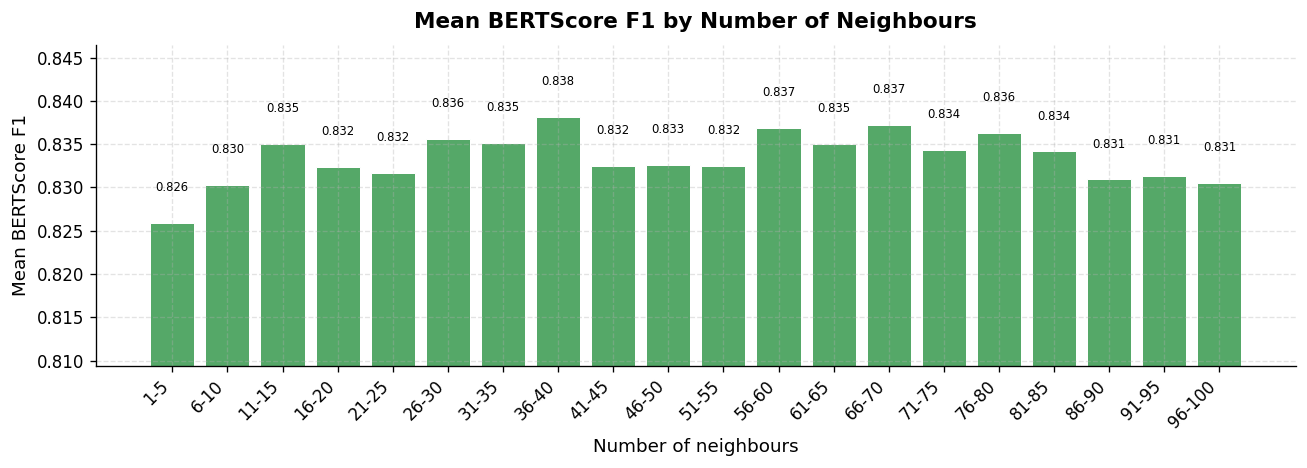

In [18]:
# ── 2. Mean BERTScore F1 ──────────────────────────────────────────────────────
bert_mean = weighted_group_mean(df, 'bertscore_f1')
ymin = bert_mean.dropna().min() * 0.98
ymax = bert_mean.dropna().max() * 1.01
bar_plot(bert_mean,
         title='Mean BERTScore F1 by Number of Neighbours',
         ylabel='Mean BERTScore F1',
         color='#55A868',
         ylim=(ymin, ymax))

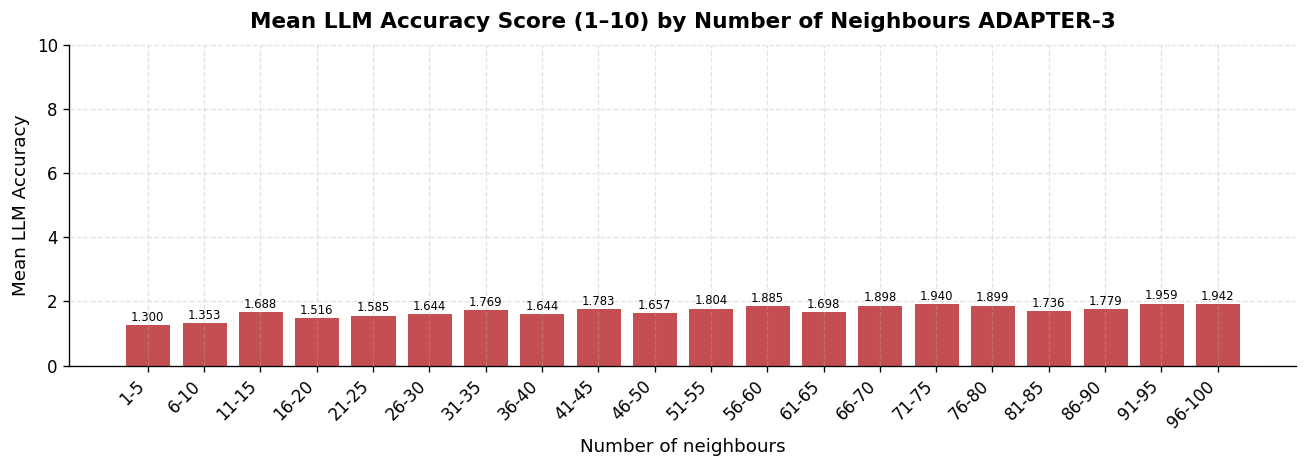

1.7365079365079366
2.0


In [19]:
# ── 3. Mean LLM Accuracy ──────────────────────────────────────────────────────
acc_mean = weighted_group_mean(df, 'llm_accuracy')
bar_plot(acc_mean,
         title='Mean LLM Accuracy Score (1–10) by Number of Neighbours ADAPTER-3',
         ylabel='Mean LLM Accuracy',
         color='#C44E52',
         ylim=(0, 10))

print(df['llm_accuracy'].mean())
print(df['llm_accuracy'].median())

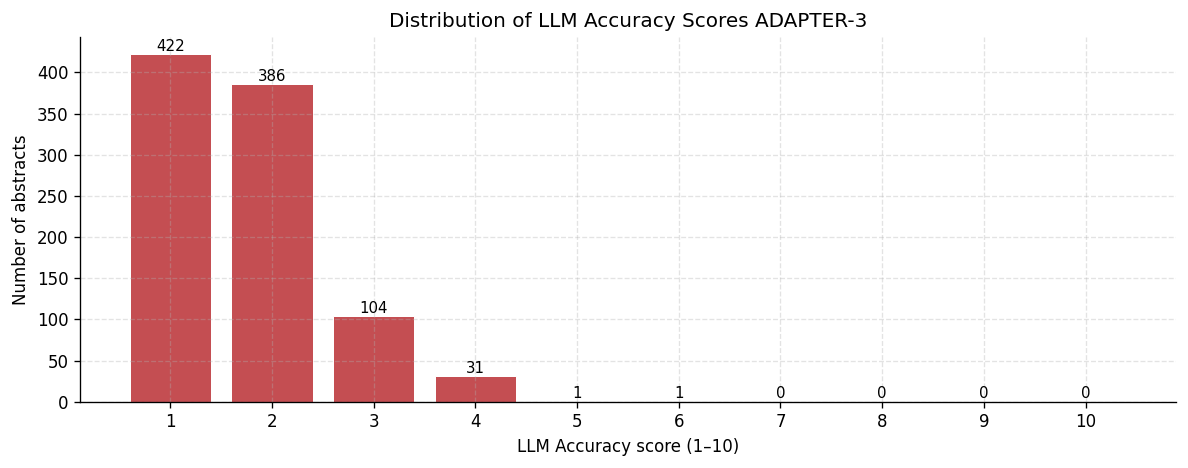

llm_accuracy
1     422
2     386
3     104
4      31
5       1
6       1
7       0
8       0
9       0
10      0
Name: count, dtype: int64

In [20]:
# ── LLM Accuracy score distribution ───────────────────────────────────────────
SCORE_RANGE = list(range(1, 11))
acc_counts = (
    df['llm_accuracy'].dropna().astype(int)
    .value_counts()
    .reindex(SCORE_RANGE, fill_value=0)
)

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(SCORE_RANGE, acc_counts.values, color='#C44E52',
              edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, acc_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)

ax.set_title('Distribution of LLM Accuracy Scores ADAPTER-3')
ax.set_xlabel('LLM Accuracy score (1–10)')
ax.set_ylabel('Number of abstracts')
ax.set_xticks(SCORE_RANGE)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.tight_layout()
plt.show()

acc_counts

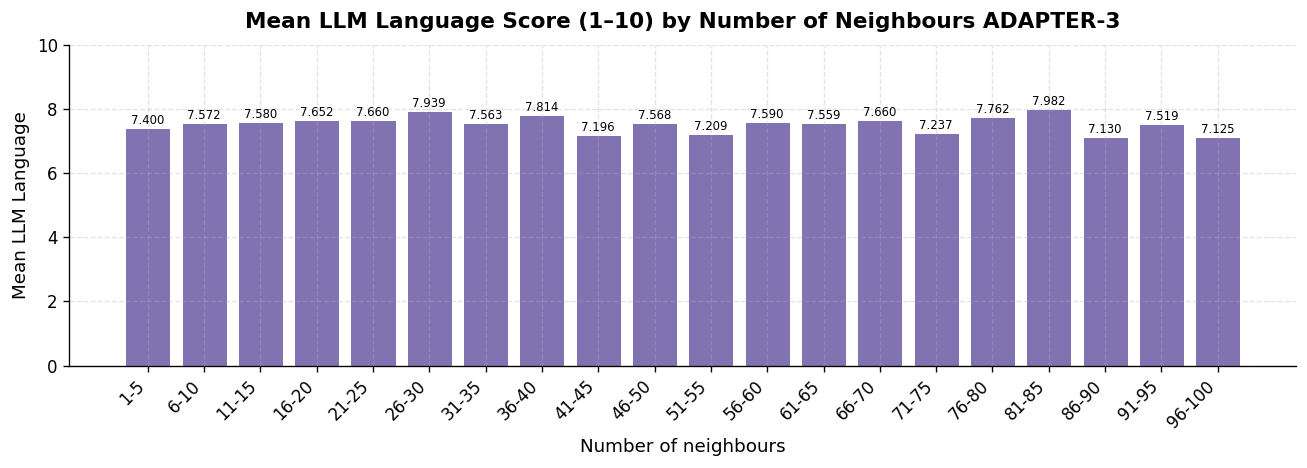

In [21]:
# ── 4. Mean LLM Language ──────────────────────────────────────────────────────
lang_mean = weighted_group_mean(df, 'llm_language')
bar_plot(lang_mean,
         title='Mean LLM Language Score (1–10) by Number of Neighbours ADAPTER-3',
         ylabel='Mean LLM Language',
         color='#8172B2',
         ylim=(0, 10))

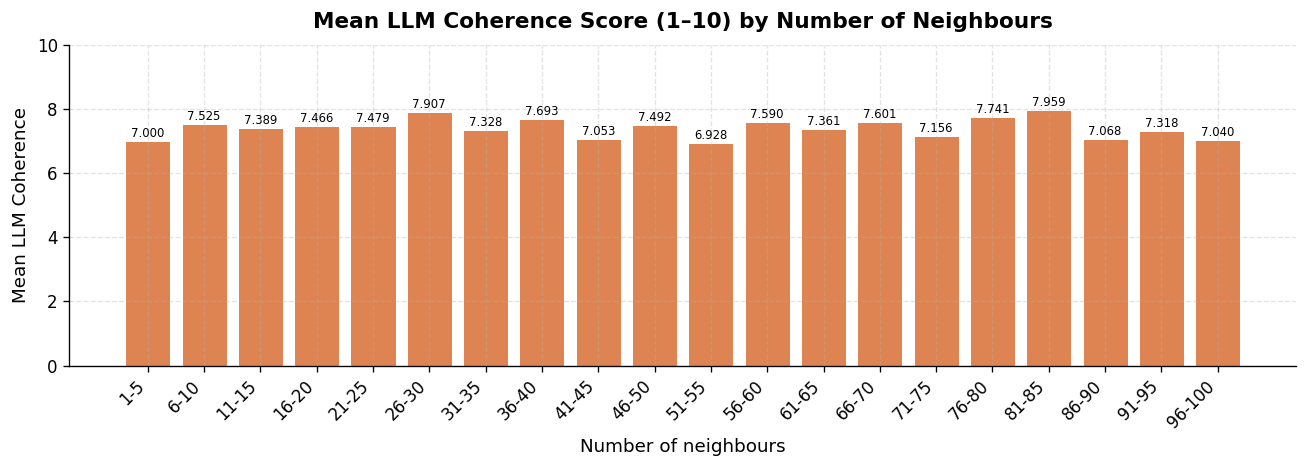

In [22]:
# ── 5. Mean LLM Coherence ─────────────────────────────────────────────────────
coh_mean = weighted_group_mean(df, 'llm_coherence')
bar_plot(coh_mean,
         title='Mean LLM Coherence Score (1–10) by Number of Neighbours',
         ylabel='Mean LLM Coherence',
         color='#DD8452',
         ylim=(0, 10))

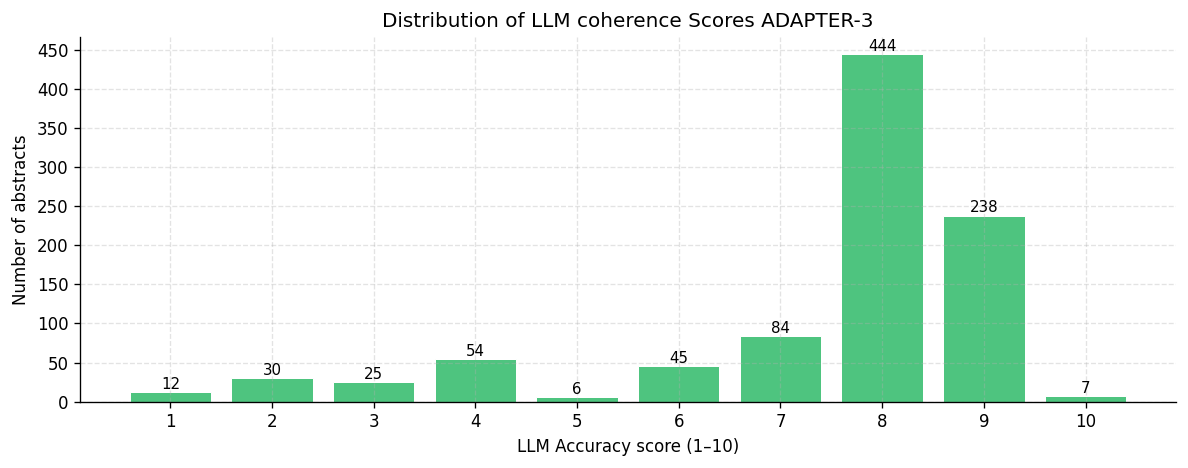

llm_coherence
1      12
2      30
3      25
4      54
5       6
6      45
7      84
8     444
9     238
10      7
Name: count, dtype: int64

In [23]:
# ── LLM Accuracy score distribution ───────────────────────────────────────────
SCORE_RANGE = list(range(1, 11))
acc_counts = (
    df['llm_coherence'].dropna().astype(int)
    .value_counts()
    .reindex(SCORE_RANGE, fill_value=0)
)

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(SCORE_RANGE, acc_counts.values, color="#4EC47F",
              edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, acc_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)

ax.set_title('Distribution of LLM coherence Scores ADAPTER-3')
ax.set_xlabel('LLM Accuracy score (1–10)')
ax.set_ylabel('Number of abstracts')
ax.set_xticks(SCORE_RANGE)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.tight_layout()
plt.show()

acc_counts

In [24]:
# ── Mean llm_accuracy excluding low-coherence (1, 2) samples ─────────────────
filtered_df = df[~df['llm_coherence'].isin([1, 2])]

print(f'Excluded {len(df) - len(filtered_df)} rows with llm_coherence in [1, 2]')
print(f'Mean llm_accuracy (all rows):      {df["llm_accuracy"].mean():.4f}')
print(f'Mean llm_accuracy (excluding 1,2): {filtered_df["llm_accuracy"].mean():.4f}')


Excluded 42 rows with llm_coherence in [1, 2]
Mean llm_accuracy (all rows):      1.7365
Mean llm_accuracy (excluding 1,2): 1.7597


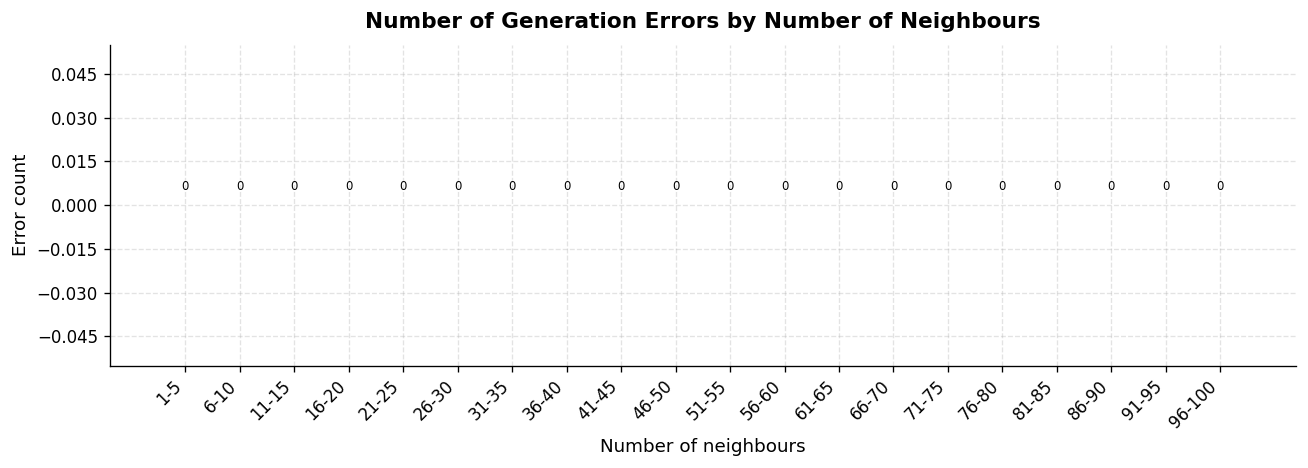

In [25]:
# ── 6. Number of Errors ───────────────────────────────────────────────────────
error_counts = df[df['is_error']].groupby('neighbor_group', observed=True).size().reindex(NEIGHBOR_GROUPS, fill_value=0)
bar_plot(error_counts,
         title='Number of Generation Errors by Number of Neighbours',
         ylabel='Error count',
         color='#CCB974',
         int_yaxis=True)

In [26]:
# ── 5 examples each of llm_coherence score 1 and 2 ───────────────────────────
low_coherence_sample = (
    df[df['llm_coherence'].isin([1, 2])]
    .sort_values('llm_coherence')
    .groupby('llm_coherence', sort=True)
    .apply(lambda g: g.head(5))
    .reset_index(drop=True)
    [['node_id', 'original_abstract', 'generated_abstract', 'llm_coherence']]
)

pd.set_option('display.max_colwidth', 2000)
low_coherence_sample


/var/folders/zc/tkfty0q10mx3n2n85rgs661h0000gn/T/ipykernel_32045/3088027966.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.head(5))


,node_id,original_abstract,generated_abstract,llm_coherence
0,91295,"Mining a set of meaningful and distinctive topics automatically from massive text corpora has broad applications. Existing topic models, however, typically work in a purely unsupervised way, which often generate topics that do not fit users' particular needs and yield suboptimal performance on downstream tasks. We propose a new task, discriminative topic mining, which leverages a set of user-provided category names to mine discriminative topics from text corpora. This new task not only helps a user understand clearly and distinctively the topics he/she is most interested in, but also benefits directly keyword-driven classification tasks. We develop CatE, a novel category-name guided text embedding method for discriminative topic mining, which effectively leverages minimal user guidance to learn a discriminative embedding space and discover category representative terms in an iterative manner. We conduct a comprehensive set of experiments to show that CatE mines high-quality set of topics guided by category names only, and benefits a variety of downstream applications including weakly-supervised classification and lexical entailment direction identification.","We present a novel approach to the problem of learning word embeddings from text corpora. Our method is based on the observation that the distribution of words in a document is a multinomial distribution, and that the distribution of words in a document is a multinomial distribution, and that the distribution of words in a document is a multinomial distribution, and that the distribution of words in a document is a multinomial distribution, and that the distribution of words in a document is a multinomial distribution, and that the distribution of words in a document is a multinomial distribution, and that the distribution of words in a document is a multinomial distribution, and that the distribution of words in a document is a multinomial distribution, and that the distribution of words in a document is a multinomial distribution, and that the distribution of words in a document is a multinomial distribution, and that the distribution of words in a document is a multinomial distribution, and that the distribution of words in a document is a multinomial distribution, and that the distribution of words in a document is a multinomial distribution, and that the distribution of words in a document is a multinomial distribution, and that the distribution of words in a document is a multinomial distribution, and that the distribution of words in a document is a multinomial distribution, and that the distribution of words in a document is a multinomial distribution, and that the distribution of words in a document is a multinomial distribution, and that the distribution of words in a document is a multinomial distribution, and that the distribution of words in a document is a multin",1
1,111914,"In uplink non-orthogonal multiple access (NOMA) networks, the order of decoding at the base station (BS) depends on the received instantaneous signal powers (ISPs). Therefore, the signal-to-interference-plus-noise ratio (SINR) coverage probability for an uplink NOMA user should be calculated using the ISP-based ranking of the users. In the existing literature, however, mean signal power (MSP)-based ranking is used to determine the decoding order and calculate the SINR coverage probability. Although this approximation provides tractable results, it is not accurate. In this letter, we derive the coverage probability for ISP-based ranking, and we show that MSP-based ranking underestimates the SINR coverage probability.","In this paper, we study the problem of energy-efficient resource allocation in a two-tier heterogeneous network (HetNet) with a macrocell and a femtocell. The femtocell is assumed to be equipped with a single antenna and the macrocell is equipped with multiple antennas. The femtocell user (FUE) is assumed

In [27]:
# ── 2 examples per llm_accuracy score ────────────────────────────────────────
sample = (
    df[df['llm_accuracy'].notna()]
    .sort_values('llm_accuracy')
    .groupby('llm_accuracy', sort=True)
    .apply(lambda g: g.head(2))
    .reset_index(drop=True)
    [['node_id', 'original_abstract', 'generated_abstract', 'llm_accuracy']]
)

pd.set_option('display.max_colwidth', 2000)
sample

/var/folders/zc/tkfty0q10mx3n2n85rgs661h0000gn/T/ipykernel_32045/263653425.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.head(2))


,node_id,original_abstract,generated_abstract,llm_accuracy
0,1089,"We deal with the \textit{selective classification} problem (supervised-learning problem with a rejection option), where we want to achieve the best performance at a certain level of coverage of the data. We transform the original $m$-class classification problem to $(m+1)$-class where the $(m+1)$-th class represents the model abstaining from making a prediction due to uncertainty. Inspired by portfolio theory, we propose a loss function for the selective classification problem based on the doubling rate of gambling. We show that minimizing this loss function has a natural interpretation as maximizing the return of a \textit{horse race}, where a player aims to balance between betting on an outcome (making a prediction) when confident and reserving one's winnings (abstaining) when not confident. This loss function allows us to train neural networks and characterize the uncertainty of prediction in an end-to-end fashion. In comparison with previous methods, our method requires almost no modification to the model inference algorithm or neural architecture. Experimentally, we show that our method can identify both uncertain and outlier data points, and achieves strong results on SVHN and CIFAR10 at various coverages of the data.",We propose a novel approach to train deep neural networks with a large number of parameters. Our method is based on the observation that the gradient of the loss function with respect to the parameters of the network is a linear combination of the gradients of the loss function with respect to the parameters of the individual layers. We show that the coefficients of this linear combination are the product of the derivatives of the activation functions of the individual layers. We use this property to derive a new algorithm for training deep neural networks. We show that our algorithm is equivalent to the backpropagation algorithm. We also show that our algorithm is more efficient than the backpropagation algorithm.,1
1,134431,"Powerful adversarial attack methods are vital for understanding how to construct robust deep neural networks (DNNs) and for thoroughly testing defense techniques. In this paper, we propose a black-box adversarial attack algorithm that can defeat both vanilla DNNs and those generated by various defense techniques developed recently. Instead of searching for an ""optimal"" adversarial example for a benign input to a targeted DNN, our algorithm finds a probability density distribution over a small region centered around the input, such that a sample drawn from this distribution is likely an adversarial example, without the need of accessing the DNN's internal layers or weights. Our approach is universal as it can successfully attack different neural networks by a single algorithm. It is also strong; according to the testing against 2 vanilla DNNs and 13 defended ones, it outperforms state-of-the-art black-box or white-box attack methods for most test cases. Additionally, our results reveal that adversarial training remains one of the best defense techniques, and the adversarial examples are not as transferable across defended DNNs as them across vanilla DNNs.",We propose a novel approach to the problem of learning a deep neural network (DNN) with a small number of parameters. Our approach is based on the observation that the number of parameters in a DNN is determined by the number of layers and the number of neurons in each layer. We propose to use a small number of layers and a small number of neurons in each layer. We show that the proposed approach can be used to learn a DNN with a small number of parameters. We also show that the proposed approach can be used to learn a DNN with a small number of parameters.,1
2,109704,"We present a novel framework for machine translation evaluation using neural networks in a pairwise setting, where the goal is to select the better translation from a pair of hypotheses, given the re

In [28]:
# ── Negative category counts ──────────────────────────────────────────────────
NEG_COLS = [
    'cat_wrong_domain', 'cat_multi_paper_contamination', 'cat_wrong_methodology',
    'cat_wrong_task', 'cat_too_generic', 'cat_truncated_incomplete',
]
NEG_LABELS = [
    'Wrong domain', 'Multi-paper contamination', 'Wrong methodology',
    'Wrong task', 'Too generic', 'Truncated / incomplete',
]

neg_counts = df[NEG_COLS].sum().values

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(NEG_LABELS, neg_counts, color='#C44E52', edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, neg_counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Count', fontsize=11)
ax.set_title('Negative category frequency', fontsize=13, fontweight='bold', pad=10)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.xticks(rotation=15, ha='right')
fig.tight_layout()
plt.show()

KeyError: "None of [Index(['cat_wrong_domain', 'cat_multi_paper_contamination',\n       'cat_wrong_methodology', 'cat_wrong_task', 'cat_too_generic',\n       'cat_truncated_incomplete'],\n      dtype='object')] are in the [columns]"

Category definitions:
- wrong_domain: The generated abstract is about a completely different research field or application domain from the original.
- multi_paper_contamination: The text reads like a stitched-together mixture of multiple unrelated papers rather than one coherent abstract.
- wrong_methodology: The domain is broadly correct but describes different techniques or algorithms than the original.
- wrong_task: Same broad field but the specific problem being solved is different (e.g., classification instead of regression, MT instead of summarisation).
- too_generic: Correct domain but described at such a high level of generality that it lacks the specific terminology and framing of the original.
- truncated_incomplete: The abstract ends abruptly mid-sentence or is clearly unfinished.


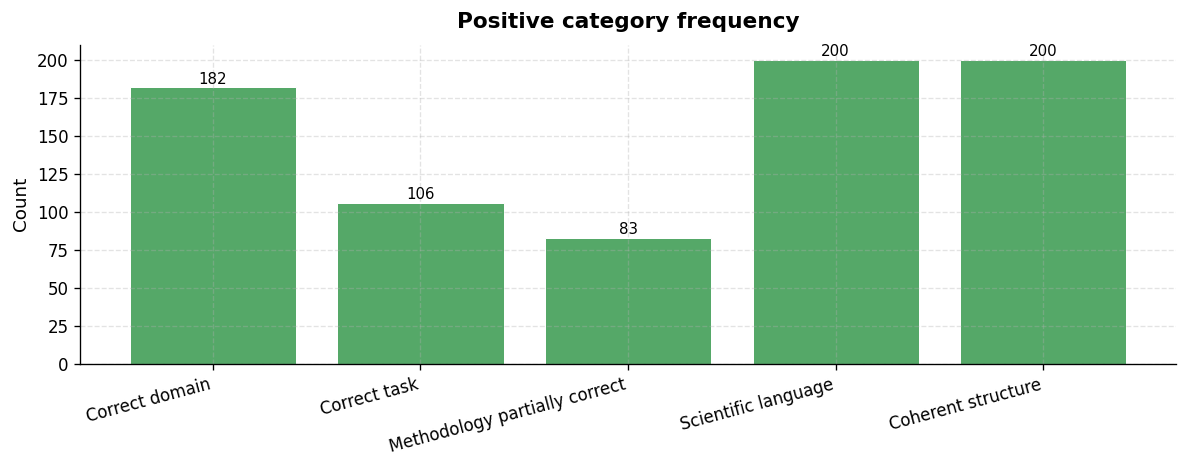

In [ ]:
# ── Positive category counts ──────────────────────────────────────────────────
POS_COLS = [
    'cat_correct_domain', 'cat_correct_task', 'cat_methodology_partially_correct',
    'cat_scientific_language', 'cat_coherent_structure',
]
POS_LABELS = [
    'Correct domain', 'Correct task', 'Methodology partially correct',
    'Scientific language', 'Coherent structure',
]

pos_counts = df[POS_COLS].sum().values

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(POS_LABELS, pos_counts, color='#55A868', edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, pos_counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Count', fontsize=11)
ax.set_title('Positive category frequency', fontsize=13, fontweight='bold', pad=10)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.xticks(rotation=15, ha='right')
fig.tight_layout()
plt.show()